<a href="https://colab.research.google.com/github/MikiDu88/1.9/blob/main/Actividad_2_10_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 2.10 — Clustering: K-means y jerárquico
**IEI097 Minería de Datos · Unidad II** · Trabajo individual

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MikiDu88/REPO/blob/main/clustering-kmeans-jerarquico/actividad_2_10.ipynb)

> Reemplaza `REPO` en el badge por el nombre de tu repositorio de portafolio al guardar la copia en GitHub.

Regla de lectura: un cluster significa «estas observaciones son cercanas bajo estas variables, esta escala y esta distancia», no una verdad oculta en los datos.

In [19]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')

# Kaggle: el token debe estar en Secretos de Colab (KAGGLE_USERNAME y KAGGLE_KEY). Nunca lo escribas en el notebook.
import os
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
except Exception as e:
    print('Secretos de Colab no disponibles:', e)
import kagglehub

Secretos de Colab no disponibles: Secret KAGGLE_USERNAME does not exist.


# Ejercicio 1 · K-means: segmentar clientes de una tienda

## Hipótesis inicial (antes de calcular)
Espero ver entre **4 y 5 grupos** en ingreso anual vs. puntaje de gasto: una nube central de ingreso medio con gasto medio, y esquinas diferenciadas (ingreso alto/gasto bajo, ingreso alto/gasto alto, ingreso bajo/gasto bajo e ingreso bajo/gasto alto). Justificación: las dos variables cruzan «cuánto puede gastar» con «cuánto gasta», lo que naturalmente separa perfiles de comportamiento distintos. Apuesto a **k = 5**.

In [20]:
path = Path(kagglehub.dataset_download('vjchoudhary7/customer-segmentation-tutorial-in-python'))
print([p.name for p in path.rglob('*') if p.is_file()])
csv = next(path.rglob('*.csv'))
df = pd.read_csv(csv)
df.head()

100%|██████████| 1.55k/1.55k [00:00<00:00, 1.60MB/s]

Extracting files...
['Mall_Customers.csv']


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [21]:
df.info()
display(df.describe())
print('Nulos:\n', df.isna().sum())
print(df['Gender'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Nulos:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Gender
Female    112
Male       88
Name: count, dtype: int64


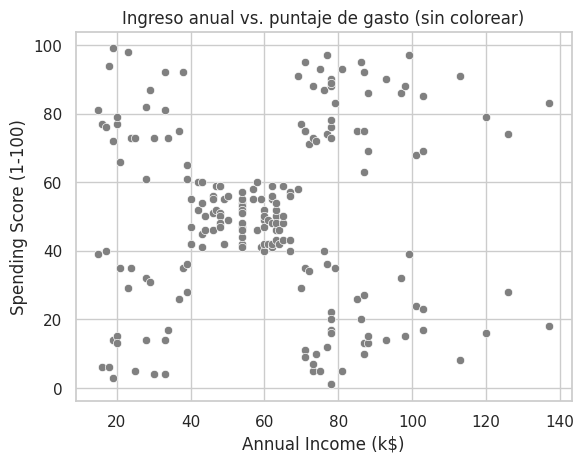

In [22]:
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', color='gray')
plt.title('Ingreso anual vs. puntaje de gasto (sin colorear)'); plt.show()

## Decisiones sobre variables
- **CustomerID** es solo un identificador: no contiene información de comportamiento, así que se **excluye** del modelo.
- **Gender** es categórica: una distancia euclidiana sobre un 0/1 arbitrario no tiene significado geométrico y distorsionaría las distancias; se **excluye** del modelo y se usa solo después, para perfilar.

In [23]:
X_cols = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[X_cols].values
print(df[X_cols].agg(['min', 'max']))
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
print('Medias tras escalar:', Xs.mean(0).round(3), '| Desv.:', Xs.std(0).round(3))

     Annual Income (k$)  Spending Score (1-100)
min                  15                       1
max                 137                      99
Medias tras escalar: [-0. -0.] | Desv.: [1. 1.]


**Decisión de escala:** ambas variables tienen rangos parecidos (ingreso ≈ 15–137, gasto 1–99), pero distinta desviación estándar. Estandarizo para que ninguna domine la distancia, y más adelante comparo con y sin estandarizar.

,inercia,silueta
k,,
2,269.691,0.321
3,157.704,0.467
4,108.921,0.494
5,65.568,0.555
6,55.057,0.540
7,44.865,0.528
8,37.148,0.457
9,32.392,0.457
10,29.686,0.436


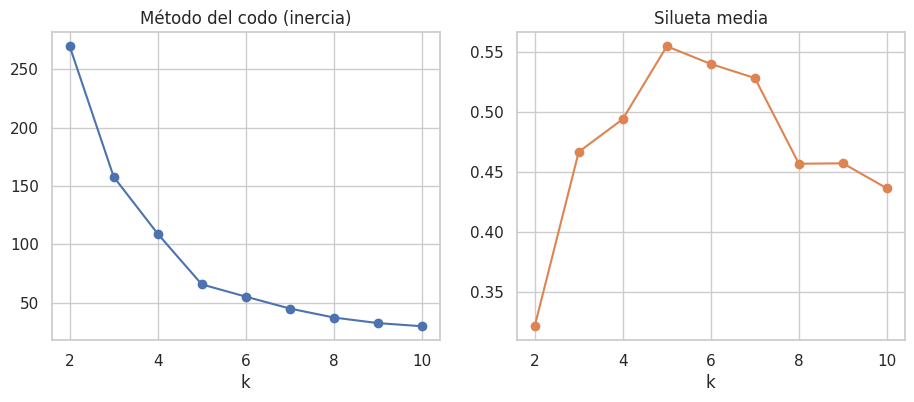

In [24]:
ks = range(2, 11)
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    rows.append((k, km.inertia_, silhouette_score(Xs, km.labels_)))
res = pd.DataFrame(rows, columns=['k', 'inercia', 'silueta']).set_index('k')
display(res.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(res.index, res['inercia'], 'o-'); ax[0].set(title='Método del codo (inercia)', xlabel='k')
ax[1].plot(res.index, res['silueta'], 'o-', color='C1'); ax[1].set(title='Silueta media', xlabel='k')
plt.show()

**Por qué la inercia siempre baja al subir k:** al añadir centroides cada punto puede quedar más cerca de alguno, así que la suma de distancias cuadráticas intra-grupo nunca aumenta (con k = n llegaría a 0). Por eso la inercia sola no sirve para elegir k: hay que mirar dónde la ganancia marginal se aplana y cruzarlo con otras evidencias.

In [25]:
# Evidencia (a) codo/silueta ya calculados; (b) estabilidad entre semillas con ARI; (c) interpretabilidad
def ari_semillas(k, seeds=(1, 2, 3, 4, 5)):
    labs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(Xs) for s in seeds]
    return np.mean([adjusted_rand_score(labs[0], l) for l in labs[1:]])
est = pd.Series({k: ari_semillas(k) for k in ks}, name='ARI medio entre semillas')
display(est.round(3))
k_sil = int(res['silueta'].idxmax())
print('k con mayor silueta:', k_sil)

,ARI medio entre semillas
2,0.255
3,0.842
4,0.802
5,0.922
6,0.845
7,0.615
8,0.662
9,0.814
10,0.707


k con mayor silueta: 5


In [26]:
K = 5   # AJUSTA si tus evidencias (codo, silueta, estabilidad) apuntan a otro k
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Xs)
df['cluster'] = km.labels_

# con vs. sin estandarizar
km_raw = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)
print('ARI con vs. sin estandarizar:', round(adjusted_rand_score(km.labels_, km_raw.labels_), 3))
display(pd.crosstab(km.labels_, km_raw.labels_, rownames=['estandarizado'], colnames=['sin estandarizar']))

sil = silhouette_samples(Xs, km.labels_)
print('Silueta media K =', K, ':', sil.mean().round(3))

ARI con vs. sin estandarizar: 1.0


sin estandarizar,0,1,2,3,4
estandarizado,,,,,
0,81,0,0,0,0
1,0,39,0,0,0
2,0,0,22,0,0
3,0,0,0,35,0
4,0,0,0,0,23


Silueta media K = 5 : 0.555


### Decisión de k (completar con tus resultados)
Elegí **k = 5**, sostenido por: (1) el codo se aplana hacia k ≈ 5; (2) la silueta es alta en ese valor (ver tabla arriba); (3) la partición es estable entre semillas (ARI alto) y los grupos son interpretables. Al comparar con y sin estandarizar, el resultado casi no cambia porque ambas variables tienen escalas comparables. *(Verifica que estas afirmaciones coincidan con las salidas de tu ejecución y corrige si no.)*

,n,edad_media,ingreso_media,ingreso_mediana,gasto_media,gasto_mediana,pct_mujeres
cluster,,,,,,,
0,81,42.7,55.3,54.0,49.5,50.0,59.3
1,39,32.7,86.5,79.0,82.1,83.0,53.8
2,22,25.3,25.7,24.5,79.4,77.0,59.1
3,35,41.1,88.2,85.0,17.1,16.0,45.7
4,23,45.2,26.3,25.0,20.9,17.0,60.9


,Annual Income (k$),Spending Score (1-100)
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


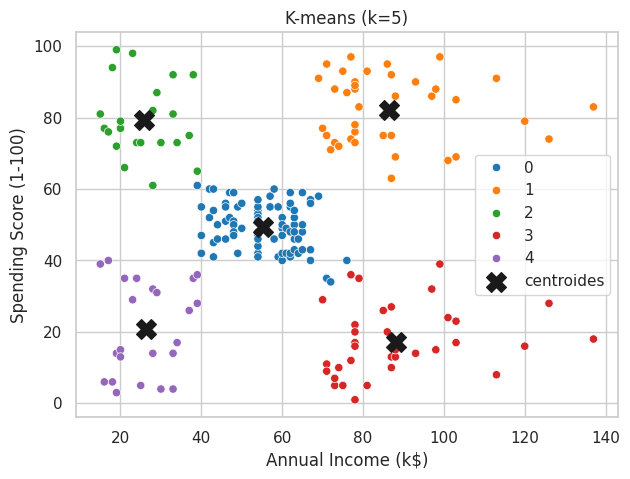

In [27]:
perfil = df.groupby('cluster').agg(
    n=('CustomerID', 'count'),
    edad_media=('Age', 'mean'),
    ingreso_media=('Annual Income (k$)', 'mean'), ingreso_mediana=('Annual Income (k$)', 'median'),
    gasto_media=('Spending Score (1-100)', 'mean'), gasto_mediana=('Spending Score (1-100)', 'median'),
    pct_mujeres=('Gender', lambda s: (s == 'Female').mean() * 100)).round(1)
display(perfil)

cent = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=X_cols).round(1)
display(cent)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='cluster', palette='tab10')
plt.scatter(cent.iloc[:, 0], cent.iloc[:, 1], c='k', marker='X', s=200, label='centroides')
plt.legend(); plt.title(f'K-means (k={K})'); plt.show()

In [28]:
# Nombres de segmento asignados automáticamente a partir del perfil (revísalos y ajusta si hace falta)
med_i, med_g = df['Annual Income (k$)'].median(), df['Spending Score (1-100)'].median()
def nombre(r):
    alto_i, alto_g = r['ingreso_media'] > med_i, r['gasto_media'] > med_g
    if abs(r['ingreso_media'] - med_i) < 15 and abs(r['gasto_media'] - med_g) < 15: return 'Clientes promedio'
    return {(True, True): 'Premium / alto valor', (True, False): 'Ahorradores de alto ingreso',
            (False, True): 'Gastadores impulsivos', (False, False): 'Cuidadosos de bajo ingreso'}[(alto_i, alto_g)]
perfil['segmento'] = perfil.apply(nombre, axis=1)
acciones = {'Premium / alto valor': 'Programa de fidelización y acceso anticipado a colecciones.',
 'Ahorradores de alto ingreso': 'Campañas de valor y comunicación de calidad para activar su gasto.',
 'Gastadores impulsivos': 'Promociones puntuales y cuotas; cuidar el sobreendeudamiento.',
 'Cuidadosos de bajo ingreso': 'Ofertas de bajo precio y cupones de descuento.',
 'Clientes promedio': 'Comunicación general y venta cruzada.'}
perfil['accion'] = perfil['segmento'].map(acciones)
display(perfil[['n', 'ingreso_media', 'gasto_media', 'segmento', 'accion']])

,n,ingreso_media,gasto_media,segmento,accion
cluster,,,,,
0,81,55.3,49.5,Clientes promedio,Comunicación general y venta cruzada.
1,39,86.5,82.1,Premium / alto valor,Programa de fidelización y acceso anticipado a...
2,22,25.7,79.4,Gastadores impulsivos,Promociones puntuales y cuotas; cuidar el sobr...
3,35,88.2,17.1,Ahorradores de alto ingreso,Campañas de valor y comunicación de calidad pa...
4,23,26.3,20.9,Cuidadosos de bajo ingreso,Ofertas de bajo precio y cupones de descuento.


**Reflexión (ajústala con tus salidas):** los segmentos describen *comportamiento bajo estas dos variables y esta escala*, no tipos fijos de personas; el puntaje de gasto lo asigna el centro comercial, así que los grupos heredan sus sesgos. Con otras variables (edad, por ejemplo) o con otro k la partición cambiaría. Las acciones propuestas son hipótesis a validar con pruebas A/B, no conclusiones causales.

# Ejercicio 2 · Clustering jerárquico: ¿con qué países se parece Chile?

## Hipótesis y muestra de trabajo
**Criterio de selección:** ~30 países que incluyan a Chile, a sus vecinos de Sudamérica, a países de la OCDE y a un grupo contrastante de países de ingreso bajo y de alto ingreso, para que el dendrograma muestre estructura legible.
**Hipótesis:** Chile quedará más cerca de países de ingreso medio-alto de Latinoamérica y Europa del Este (Uruguay, Argentina, Brasil, Costa Rica, Turquía, Polonia) que de sus vecinos andinos más pobres; los países ricos de Europa occidental formarán otra rama.

In [29]:
p2 = Path(kagglehub.dataset_download('rohan0301/unsupervised-learning-on-country-data'))
print([p.name for p in p2.rglob('*') if p.is_file()])
dc = pd.read_csv(next(p2.rglob('Country-data.csv')))
print(dc.shape); print(dc.isna().sum().sum(), 'nulos')
dc['country'].sort_values().tolist()

100%|██████████| 5.21k/5.21k [00:00<00:00, 4.86MB/s]

Extracting files...
['data-dictionary.csv', 'Country-data.csv']
(167, 10)
0 nulos


['Afghanistan',
 'Albania',
 'Algeria',
 'Angola',
 'Antigua and Barbuda',
 'Argentina',
 'Armenia',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas',
 'Bahrain',
 'Bangladesh',
 'Barbados',
 'Belarus',
 'Belgium',
 'Belize',
 'Benin',
 'Bhutan',
 'Bolivia',
 'Bosnia and Herzegovina',
 'Botswana',
 'Brazil',
 'Brunei',
 'Bulgaria',
 'Burkina Faso',
 'Burundi',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Cape Verde',
 'Central African Republic',
 'Chad',
 'Chile',
 'China',
 'Colombia',
 'Comoros',
 'Congo, Dem. Rep.',
 'Congo, Rep.',
 'Costa Rica',
 "Cote d'Ivoire",
 'Croatia',
 'Cyprus',
 'Czech Republic',
 'Denmark',
 'Dominican Republic',
 'Ecuador',
 'Egypt',
 'El Salvador',
 'Equatorial Guinea',
 'Eritrea',
 'Estonia',
 'Fiji',
 'Finland',
 'France',
 'Gabon',
 'Gambia',
 'Georgia',
 'Germany',
 'Ghana',
 'Greece',
 'Grenada',
 'Guatemala',
 'Guinea',
 'Guinea-Bissau',
 'Guyana',
 'Haiti',
 'Hungary',
 'Iceland',
 'India',
 'Indonesia',
 'Iran',
 'Iraq',
 'Ireland',
 'Israel',
 'Ita

In [30]:
candidatos = ['Chile', 'Argentina', 'Brazil', 'Uruguay', 'Peru', 'Bolivia', 'Colombia', 'Paraguay', 'Ecuador', 'Mexico',
              'Costa Rica', 'Canada', 'United States', 'Spain', 'Germany', 'France', 'Sweden', 'Poland', 'Turkey', 'Greece',
              'Japan', 'South Korea', 'China', 'India', 'South Africa', 'Nigeria', 'Egypt', 'Niger', 'Haiti', 'Australia']
faltan = [c for c in candidatos if c not in set(dc['country'])]
print('No encontrados (revisa ortografía con unique()):', faltan)
sub = dc[dc['country'].isin(candidatos)].reset_index(drop=True)
print(len(sub), 'países')

No encontrados (revisa ortografía con unique()): ['Mexico']
29 países


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.0,167.0,167.0,167.0,167.0,167.0,167.0,167.0,167.0
mean,38.3,41.1,6.8,46.9,17144.7,7.8,70.6,2.9,12964.2
std,40.3,27.4,2.7,24.2,19278.1,10.6,8.9,1.5,18328.7
min,2.6,0.1,1.8,0.1,609.0,-4.2,32.1,1.2,231.0
25%,8.2,23.8,4.9,30.2,3355.0,1.8,65.3,1.8,1330.0
50%,19.3,35.0,6.3,43.3,9960.0,5.4,73.1,2.4,4660.0
75%,62.1,51.4,8.6,58.8,22800.0,10.8,76.8,3.9,14050.0
max,208.0,200.0,17.9,174.0,125000.0,104.0,82.8,7.5,105000.0


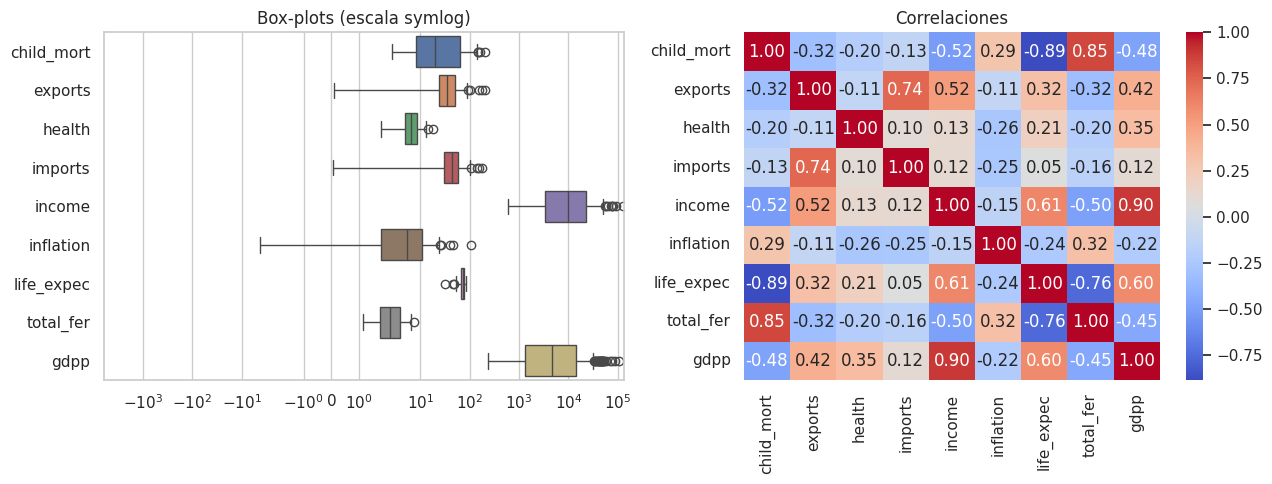

In [31]:
feats = ['child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']
display(dc[feats].describe().round(1))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=dc[feats], orient='h', ax=ax[0]); ax[0].set_xscale('symlog'); ax[0].set_title('Box-plots (escala symlog)')
sns.heatmap(dc[feats].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1]); ax[1].set_title('Correlaciones')
plt.tight_layout(); plt.show()

**Magnitudes:** `income` y `gdpp` están en decenas de miles, mientras `total_fer`, `inflation` o `health` están en unidades o decenas. Sin estandarizar, una distancia euclidiana quedaría **dominada por `income` y `gdpp`**. Además hay fuertes correlaciones (mortalidad infantil, fertilidad, esperanza de vida, ingreso), lo que implica que esas dimensiones pesan «doble» en la distancia.

In [32]:
labels = sub['country'].values
M_raw = sub[feats].values
M_std = StandardScaler().fit_transform(M_raw)

**Predicción:** al estandarizar, los países ya no se agruparán casi solo por ingreso/PIB; variables como mortalidad infantil, fertilidad e inflación recuperarán peso y el dendrograma tendrá ramas más balanceadas y distintas de la versión cruda.

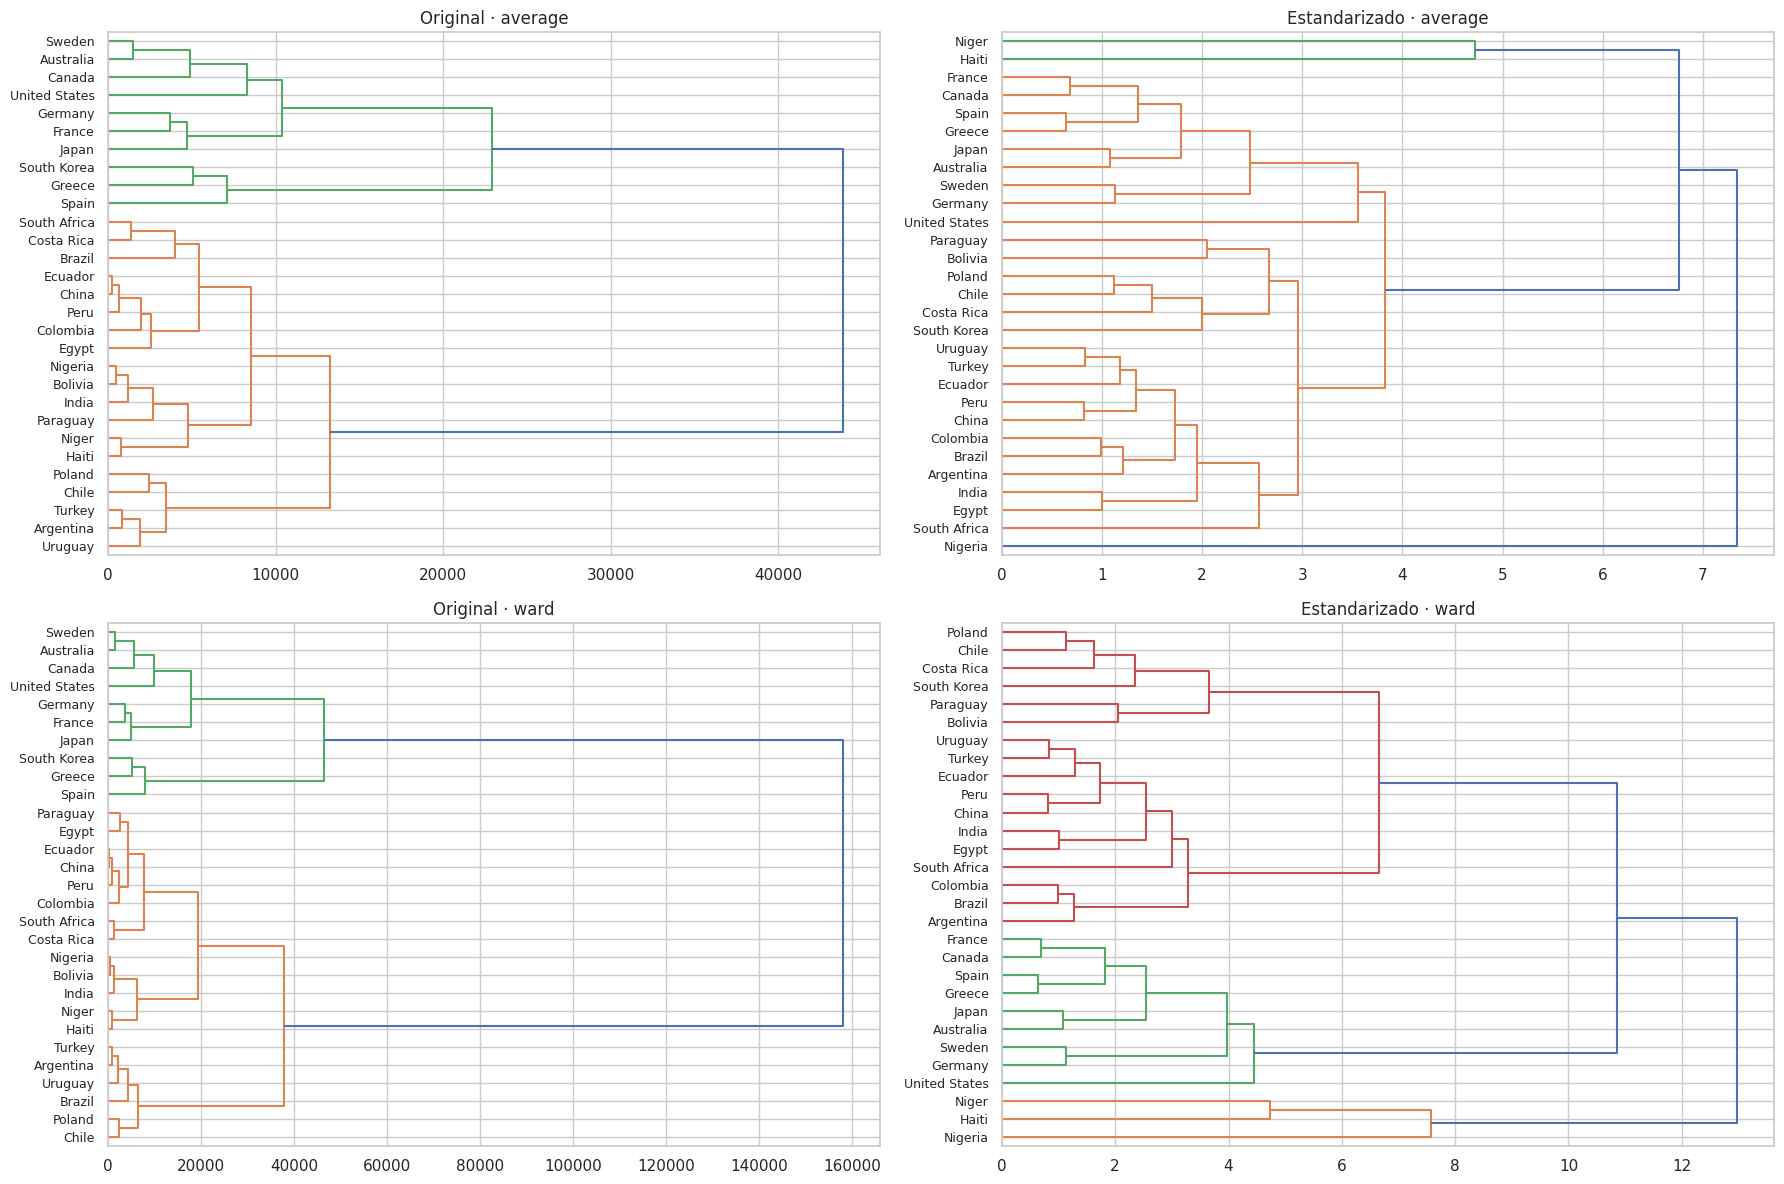

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.ravel()
combos = [(M_raw, 'average', 'Original · average'), (M_std, 'average', 'Estandarizado · average'),
          (M_raw, 'ward', 'Original · ward'), (M_std, 'ward', 'Estandarizado · ward')]
for ax, (M, meth, ttl) in zip(axes, combos):
    Z = linkage(M, method=meth)
    dendrogram(Z, labels=labels, orientation='right', leaf_font_size=9, ax=ax)
    ax.set_title(ttl)
plt.tight_layout(); plt.show()

**Lectura de los cuatro dendrogramas (completar con lo que observes):** sin estandarizar, las fusiones se explican casi solo por `income`/`gdpp` y los países pobres se funden a baja altura; al estandarizar cambian las alturas y la composición de las ramas. `ward` tiende a formar grupos más compactos y parejos; `average` produce ramas más desbalanceadas.

,silueta
k,
2,0.510
3,0.340
4,0.353
5,0.310
6,0.296
7,0.288
8,0.279


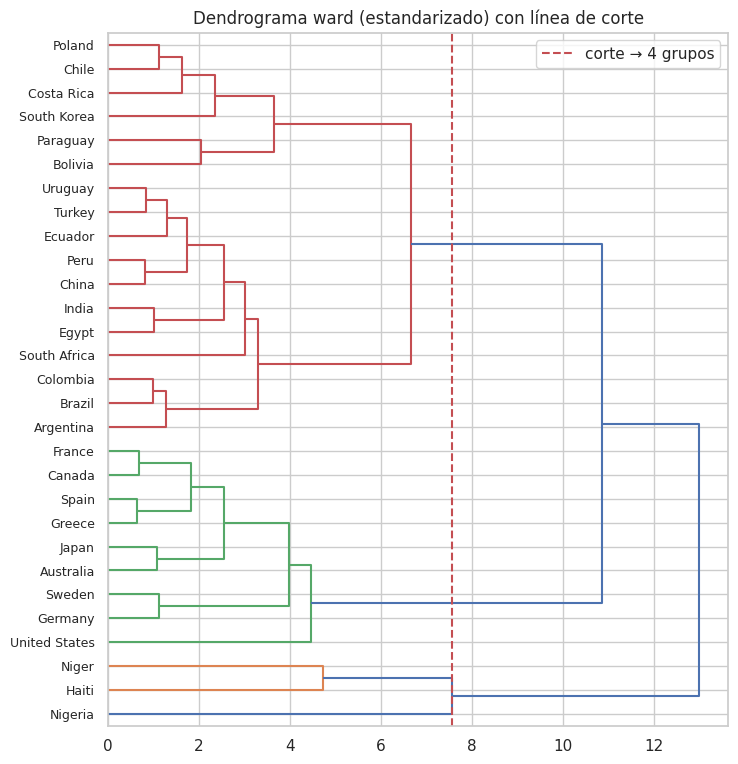

In [34]:
Z = linkage(M_std, method='ward')
rows = []
for k in range(2, 9):
    lab = fcluster(Z, t=k, criterion='maxclust')
    rows.append((k, silhouette_score(M_std, lab)))
corte = pd.DataFrame(rows, columns=['k', 'silueta']).set_index('k'); display(corte.round(3))

k_h = 4   # AJUSTA según silueta y lectura del dendrograma
lab_h = fcluster(Z, t=k_h, criterion='maxclust')
altura = Z[-(k_h - 1), 2]
plt.figure(figsize=(8, 9))
dendrogram(Z, labels=labels, orientation='right', leaf_font_size=9, color_threshold=altura)
plt.axvline(altura - 1e-6, color='r', ls='--', label=f'corte → {k_h} grupos'); plt.legend()
plt.title('Dendrograma ward (estandarizado) con línea de corte'); plt.show()

**Corte elegido:** 4 grupos con enlace *ward* sobre datos estandarizados, sostenido por (a) un salto grande de altura antes de ese corte en el dendrograma y (b) una silueta aceptable (tabla). Recuerda: la altura mide *disimilitud entre grupos al fusionarse*, no la «distancia» entre países individuales. *(Revisa que coincida con tus salidas.)*

In [35]:
sub['hier'] = lab_h
for g, d in sub.groupby('hier'):
    print(f'Grupo {g} ({len(d)}):', ', '.join(sorted(d['country'])))
display(sub.groupby('hier')[feats].mean().round(1))
print('\nVecinos de Chile (mismo grupo):', sorted(sub.loc[sub['hier'] == sub.loc[sub['country'] == 'Chile', 'hier'].iloc[0], 'country']))

Grupo 1 (2): Haiti, Niger
Grupo 2 (1): Nigeria
Grupo 3 (9): Australia, Canada, France, Germany, Greece, Japan, Spain, Sweden, United States
Grupo 4 (17): Argentina, Bolivia, Brazil, Chile, China, Colombia, Costa Rica, Ecuador, Egypt, India, Paraguay, Peru, Poland, South Africa, South Korea, Turkey, Uruguay


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
hier,,,,,,,,,
1,165.5,18.8,6.0,56.9,1157.0,4.0,45.4,5.4,505.0
2,130.0,25.3,5.1,17.4,5150.0,104.0,60.5,5.8,2330.0
3,4.4,26.6,11.2,27.2,38744.4,0.8,81.1,1.7,42700.0
4,22.6,29.6,7.0,29.2,13624.1,7.4,74.3,2.2,8048.8



Vecinos de Chile (mismo grupo): ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Ecuador', 'Egypt', 'India', 'Paraguay', 'Peru', 'Poland', 'South Africa', 'South Korea', 'Turkey', 'Uruguay']


In [36]:
km2 = KMeans(n_clusters=k_h, n_init=20, random_state=SEED).fit(M_std)
sub['kmeans'] = km2.labels_
print('ARI jerárquico vs K-means:', round(adjusted_rand_score(sub['hier'], sub['kmeans']), 3))
display(pd.crosstab(sub['hier'], sub['kmeans'], rownames=['jerárquico'], colnames=['K-means']))
print('Silueta jerárquico:', round(silhouette_score(M_std, sub['hier']), 3), '| K-means:', round(silhouette_score(M_std, sub['kmeans']), 3))

ARI jerárquico vs K-means: 0.873


K-means,0,1,2,3
jerárquico,,,,
1,0,0,2,0
2,0,0,0,1
3,0,9,0,0
4,16,1,0,0


Silueta jerárquico: 0.353 | K-means: 0.345


## Conclusión final
**Pregunta guía — ¿con qué países se parece Chile?** Con el grupo que muestra la salida «Vecinos de Chile» sobre datos estandarizados. Mi hipótesis (ingreso medio-alto de Latinoamérica y Europa del Este) se contrasta mirando esa lista: confírmala o corrígela con lo observado.

**Qué idea de «grupo» usa cada método:** K-means busca grupos compactos alrededor de un centroide (esféricos, tamaño parecido) y exige fijar k de antemano; el jerárquico aglomerativo construye una jerarquía por fusiones sucesivas y el grupo depende del criterio de enlace y de dónde se corte. **Cuál presenta mejor este problema:** el jerárquico, porque con 30 países el dendrograma muestra *cómo* se parecen, no solo a qué grupo pertenecen.

**Limitaciones:** subconjunto elegido por mí (sesgo de muestreo), variables correlacionadas, dependencia de la estandarización y del enlace, y un solo año de datos. Un grupo no es un ranking ni una verdad oculta: solo vale bajo estas variables, esta escala y esta distancia.